# Are the d1 photos really the same place as the new base map?

The score fell when the map changed. Before blaming the matcher, check the map itself: put each thermal photo on the map **at its true position** (from the metadata) and let LoFTR match it, once on the old map (`small_sat_area`) and once on the new two-scene map.

* If the new map is georeferenced like the photos, the match at the true position has plenty of inliers and the correction is a few metres, as on the old map.
* If it is shifted, **every** photo shows the same offset (a constant arrow), and the inliers drop.
* A different date or sensor (new: CARTOSAT-3 pan, Feb 2025; old: Pleiades Neo, Jan 2026) lowers the inliers a little but does not move the correction.

In [1]:
import os, sys, math
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd()
while not (ROOT / "single_photo_pipeline.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT / "src")); os.chdir(ROOT)
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "")           # the GPU may be busy with another notebook; 40 pairs are fast enough on the CPU

from train.datasets import photo_sets
from train import config
from header import map_source, settings
from image_processing.geometry import render_query
from image_processing.map_levels import build_level_pictures, level_gsd, map_piece
from fine_matching.loftr_matcher import load_loftr_matcher, prepare_roma_canvas, check_candidate_loftr

N = 40
old = photo_sets.load_official_photos(500, 7, map_files=map_source.OLD_MAP)            # the old map
new = photo_sets.load_official_photos(500, 7, margin_m=800)              # the new map, cut around the photos
print("old map %d x %d px | new map %d x %d px" % (old["satellite_map"].width, old["satellite_map"].height, new["satellite_map"].width, new["satellite_map"].height))

old map 22096 x 13840 px | new map 11267 x 10415 px


## 1 · The map pictures and the matcher

In [2]:
old_levels = build_level_pictures(old["satellite_map"])
new_levels = build_level_pictures(new["satellite_map"])
matcher = load_loftr_matcher(config.find_nudt_dir() / "checkpoint" / "MINIMA" / "minima_loftr.ckpt")
test_set = old["test_set"]; camera = old["camera"]
order = np.linspace(0, len(test_set.items) - 1, N).astype(int)           # photos spread over all flights
print("photos checked:", len(order))

/home/voidness/Storage/Synced Folders/InterIIT Tech 15/venv-geoloc/lib/python3.10/site-packages/kornia/feature/lightglue.py:44: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @torch.cuda.amp.custom_fwd(cast_inputs=torch.float32)


photos checked: 40


## 2 · Match every photo at its true position, on both maps

`shift` is the correction LoFTR + RANSAC asks for at the true position (metres, x right / y down). It should be near zero if photo and map agree.

In [3]:
rows = []; kept = {}
for i in order:
    item = test_set.items[i]; level = int(test_set.query_levels[i])
    canvas, valid = render_query(item, camera, level)
    picture, reliable = prepare_roma_canvas(canvas, valid)
    row = dict(photo=int(i), height=item["rel_height"], level=level)
    for name, pack in (("old", old), ("new", new)):
        smap = pack["satellite_map"]
        r, c = smap.gps_to_map_pixel(item["lat"], item["lon"])
        x, y = c * smap.gsd, r * smap.gsd
        levels = old_levels if name == "old" else new_levels
        found = check_candidate_loftr(matcher, picture, reliable, levels, level, x, y)
        row[name + "_inliers"] = found["n_inliers"]; row[name + "_dx"] = found["shift"][0]; row[name + "_dy"] = found["shift"][1]
        kept[(int(i), name)] = (picture, found["tile"])
    rows.append(row)
table = pd.DataFrame(rows)
display(table.head(8).round(1))

,photo,height,level,old_inliers,old_dx,old_dy,new_inliers,new_dx,new_dy
0,0,105.1,3,86,3.2,-0.3,33,0.3,-1.0
1,9,300.5,6,35,11.5,2.5,16,5.9,0.4
2,19,170.2,5,61,6.2,0.5,32,2.0,-3.7
3,29,350.2,7,29,0.7,-0.9,31,-2.2,-3.8
4,38,300.0,6,49,13.3,5.1,44,4.3,1.8
5,48,279.9,6,167,6.9,-4.3,138,1.6,-4.8
6,58,100.6,3,49,0.0,-0.8,4,0.8,-4.4
7,67,150.1,4,103,-0.1,2.0,10,-2.9,-3.9


## 3 · Reading it

old map: median inliers  49 | photos with >= 6 inliers: 36 of 40 | median shift of those: dx +3.3 m, dy -0.1 m | scatter (std) dx 4.2, dy 3.4
new map: median inliers  22 | photos with >= 6 inliers: 35 of 40 | median shift of those: dx +0.2 m, dy -3.5 m | scatter (std) dx 3.8, dy 4.0


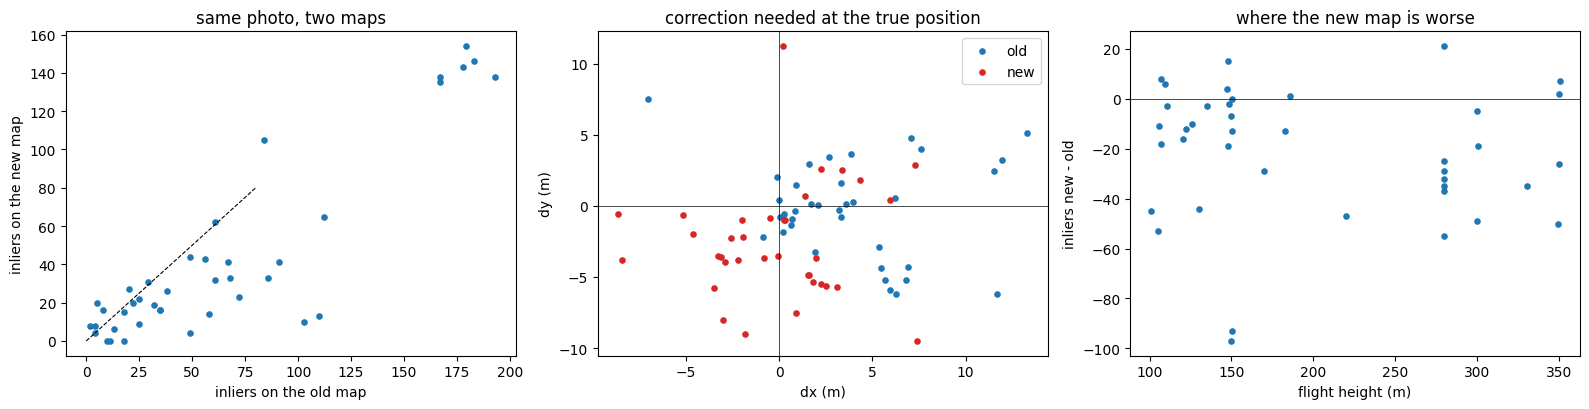

In [4]:
for name in ("old", "new"):
    good = table[name + "_inliers"] >= 6
    print("%-3s map: median inliers %3.0f | photos with >= 6 inliers: %2d of %d | median shift of those: dx %+.1f m, dy %+.1f m | scatter (std) dx %.1f, dy %.1f" % (
        name, table[name + "_inliers"].median(), good.sum(), len(table), table.loc[good, name + "_dx"].median(), table.loc[good, name + "_dy"].median(),
        table.loc[good, name + "_dx"].std(), table.loc[good, name + "_dy"].std()))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].scatter(table["old_inliers"], table["new_inliers"], s=14); axes[0].plot([0, 80], [0, 80], "k--", lw=0.8)
axes[0].set_xlabel("inliers on the old map"); axes[0].set_ylabel("inliers on the new map"); axes[0].set_title("same photo, two maps")
for name, colour in (("old", "tab:blue"), ("new", "tab:red")):
    good = table[name + "_inliers"] >= 6
    axes[1].scatter(table.loc[good, name + "_dx"], table.loc[good, name + "_dy"], s=14, c=colour, label=name)
axes[1].axhline(0, c="k", lw=0.5); axes[1].axvline(0, c="k", lw=0.5); axes[1].set_xlabel("dx (m)"); axes[1].set_ylabel("dy (m)"); axes[1].legend(); axes[1].set_title("correction needed at the true position")
axes[2].scatter(table["height"], table["new_inliers"] - table["old_inliers"], s=14); axes[2].axhline(0, c="k", lw=0.5)
axes[2].set_xlabel("flight height (m)"); axes[2].set_ylabel("inliers new - old"); axes[2].set_title("where the new map is worse")
plt.tight_layout(); plt.show()

## 4 · Look at three photos: canvas, old map tile, new map tile (all at the true position)

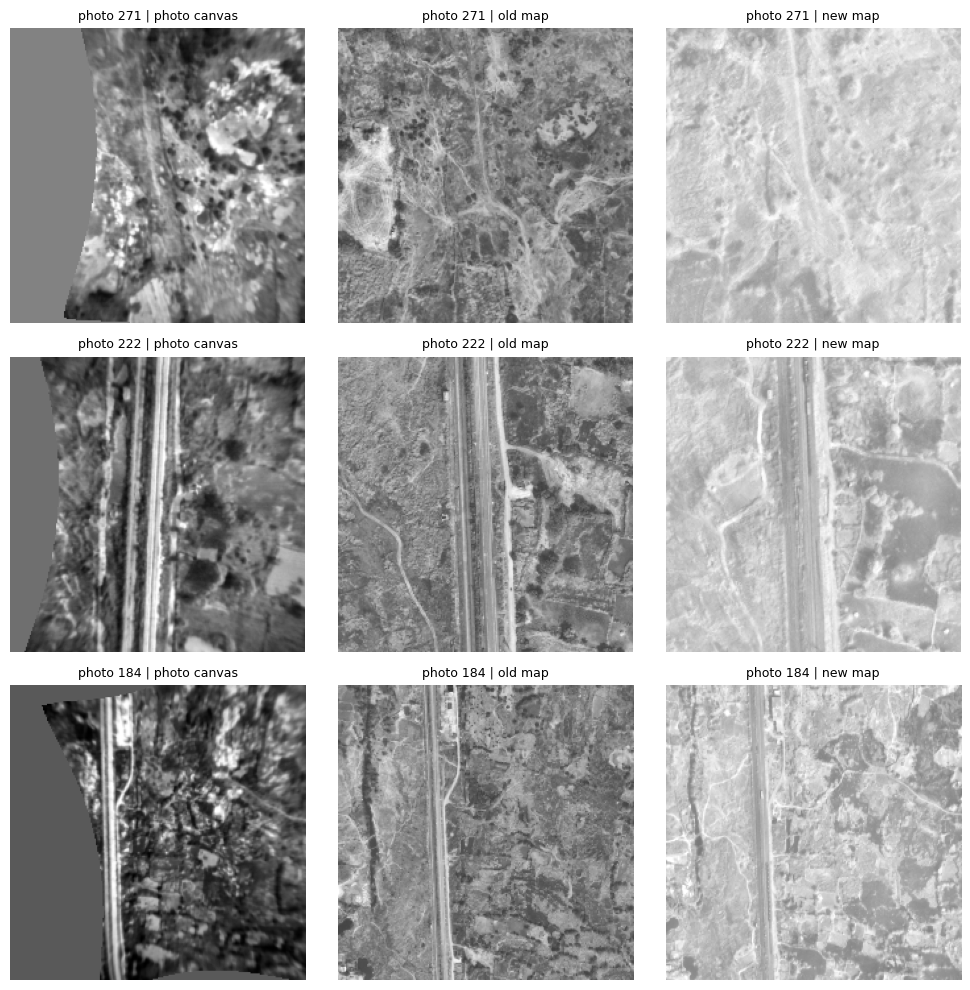

In [5]:
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
picks = [int(table.sort_values("height").iloc[k]["photo"]) for k in (2, len(table) // 2, len(table) - 3)]
for r, i in enumerate(picks):
    for c, (name, tile_of) in enumerate((("photo canvas", None), ("old map", "old"), ("new map", "new"))):
        picture, _ = kept[(i, "old")]
        image = picture if tile_of is None else kept[(i, tile_of)][1]
        axes[r, c].imshow(image, cmap="gray", vmin=0, vmax=1); axes[r, c].axis("off")
        axes[r, c].set_title("photo %d | %s" % (i, name), fontsize=9)
plt.tight_layout(); plt.show()